# Insurance Customer Response Prediction
### Predicting which customers will say "yes" to a vehicle insurance cross-sell offer

**Goal:** Build a classification model that predicts whether an existing health-insurance customer will respond positively (`Response = 1`) to a vehicle insurance offer, so the company can target marketing more efficiently.

**Notebook roadmap:**
1. Load & inspect the data
2. Exploratory Data Analysis (EDA)
3. Feature engineering & encoding
4. Train/test split + handling class imbalance (SMOTE)
5. Model training — Logistic Regression, Decision Tree, Random Forest
6. Model evaluation & comparison
7. Explainability with SHAP
8. Conclusions & business recommendations



## 1. Import Libraries
We use `pandas`/`numpy` for data handling, `plotly` for interactive charts (as requested), `scikit-learn` for modelling, `imbalanced-learn` for SMOTE, and `shap` for model explainability.

In [2]:
# --- Core data handling ---
import pandas as pd
import numpy as np

# --- Visualization (Plotly, per project requirement) ---
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Machine Learning ---
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, confusion_matrix,
                              classification_report)
from scipy.stats import randint
from imblearn.pipeline import Pipeline

# --- Handling class imbalance ---
from imblearn.over_sampling import SMOTE

# --- Explainability ---
import shap
import matplotlib.pyplot as plt

# --- Saving the model ---
import joblib
import json
from pathlib import Path

# --- Misc ---
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# A consistent colour palette used across all charts in this notebook
PALETTE = px.colors.qualitative.Set2
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load & First Look at the Data

In [ ]:
# Load the dataset
df = pd.read_csv("data.csv")

# Basic shape and a peek at the first few rows
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()


Rows: 381,109  |  Columns: 12


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [7]:
# Data types and non-null counts -- quick structural check
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


**Inference:**
- The dataset has **381,109 customers** and **12 columns**.
- `Response` is our **target variable** (1 = customer accepted the offer, 0 = declined).
- Columns like `Gender`, `Vehicle_Age`, `Vehicle_Damage` are categorical (text); the rest are numeric.
- `Region_Code` and `Policy_Sales_Channel` are stored as numbers but are really **ID codes**, not true numeric quantities -- we'll treat them as such.

In [8]:
# Check for missing values in every column
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")

# Check for fully duplicated rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")


Missing values per column:
No missing values found.

Duplicate rows: 0


**Inference:** The dataset is clean -- **no missing values and no duplicate rows**, so we don't need imputation or de-duplication. This is unusual for real-world data but makes preprocessing simpler here.

In [9]:
# Summary statistics for numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
id,381109.0,190555.000000,110016.836208,1.0,95278.0,190555.0,285832.0,381109.0
Age,381109.0,38.822584,15.511611,20.0,25.0,36.0,49.0,85.0
Driving_License,381109.0,0.997869,0.046110,0.0,1.0,1.0,1.0,1.0
Region_Code,381109.0,26.388807,13.229888,0.0,15.0,28.0,35.0,52.0
Previously_Insured,381109.0,0.458210,0.498251,0.0,0.0,0.0,1.0,1.0
Annual_Premium,381109.0,30564.389581,17213.155057,2630.0,24405.0,31669.0,39400.0,540165.0
Policy_Sales_Channel,381109.0,112.034295,54.203995,1.0,29.0,133.0,152.0,163.0
Vintage,381109.0,154.347397,83.671304,10.0,82.0,154.0,227.0,299.0
Response,381109.0,0.122563,0.327936,0.0,0.0,0.0,0.0,1.0


**Inference:**
- `Age` ranges from 20 to 85, with a median around 36 -- a fairly young-to-middle-aged customer base.
- `Annual_Premium` has a **huge range** (2,630 to 540,165) -- the maximum is over 15x the median (31,669), a sign of a **long right tail and outliers** we should visualize. Note that the mean (30,564) is actually slightly *below* the median: about 17% of customers sit exactly on the minimum premium of 2,630, which pulls the mean down and offsets the high-value tail.
- `Vintage` (days as a customer) is fairly evenly spread between 10 and 299 days.

## 3. Target Variable: `Response`

In [10]:
# Count and percentage of each class
resp_counts = df['Response'].value_counts().reset_index()
resp_counts.columns = ['Response', 'Count']
resp_counts['Response'] = resp_counts['Response'].map({0: 'Not Interested (0)', 1: 'Interested (1)'})
resp_counts['Percent'] = (resp_counts['Count'] / resp_counts['Count'].sum() * 100).round(2)

fig = px.pie(resp_counts, names='Response', values='Count', hole=0.45,
             color_discrete_sequence=PALETTE,
             title='Customer Response Distribution (Target Variable)')
fig.update_traces(textinfo='label+percent')
fig.show()

print(resp_counts)


             Response   Count  Percent
0  Not Interested (0)  334399    87.74
1      Interested (1)   46710    12.26


**Inference -- Class Imbalance:**
Only **~12.3%** of customers responded positively, while **~87.7%** said no. This is a classic **imbalanced classification problem**. If we train a model naively, it can score ~88% accuracy just by predicting "No" for everyone -- which is useless for the business. 

## 4. Distribution of Numeric Features

In [11]:
# We pre-aggregate into histogram bins with numpy before plotting.
# Reason: the raw dataset has 381k rows -- plotting raw points would create a very heavy,
# slow-to-render chart. Pre-binning keeps the chart light and just as informative.

def plot_hist(series, title, nbins=40, color='#66c2a5'):
    counts, edges = np.histogram(series.dropna(), bins=nbins)
    centers = (edges[:-1] + edges[1:]) / 2
    fig = go.Figure(go.Bar(x=centers, y=counts, marker_color=color))
    fig.update_layout(title=title, xaxis_title=series.name, yaxis_title='Number of Customers',
                       bargap=0.02)
    fig.show()

plot_hist(df['Age'], 'Distribution of Customer Age', color=PALETTE[0])
plot_hist(df['Annual_Premium'], 'Distribution of Annual Premium', color=PALETTE[1])
plot_hist(df['Vintage'], 'Distribution of Vintage (days as customer)', color=PALETTE[2])


**Inference:**
- **Age** is right-skewed with a large concentration of customers in their **20s-30s**, and a secondary bump around **40-50** -- likely two different customer segments (new young customers vs. established mid-life customers).
- **Annual_Premium** has a long **right tail** (skewness about 1.8) of very high premiums -- confirms the outliers we saw in `describe()`. Most customers sit in a tight band (roughly 24k-39k), and the first bar is inflated by the ~17% of customers sitting exactly on the 2,630 minimum, which looks like a floor value. Tree-based models handle this fine, but it's worth knowing for Logistic Regression, which we'll scale.
- **Vintage** is almost **uniformly distributed**, suggesting it's closer to a randomly-assigned "days since joined" counter than a naturally clustered variable.

In [12]:
# Boxplot for Annual_Premium to visualize outliers explicitly.
# We sample 8,000 rows purely for rendering speed -- the distribution shape is preserved.
sample_premium = df['Annual_Premium'].sample(8000, random_state=42)
fig = px.box(sample_premium, points=False, color_discrete_sequence=[PALETTE[3]],
             title='Annual Premium -- Outlier Check (8,000-row sample)')
fig.update_layout(yaxis_title='Annual Premium')
fig.show()


**Inference:** There is a substantial number of high-value outliers above the upper whisker. We will **not remove** them -- high premium is a legitimate real-world signal (some customers simply have expensive policies) and tree-based models are robust to it. We'll keep this in mind if Logistic Regression underperforms.

## 5. Distribution of Categorical Features

In [13]:
cat_cols = ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Driving_License', 'Previously_Insured']

fig = make_subplots(rows=2, cols=3, subplot_titles=cat_cols)
positions = [(1,1),(1,2),(1,3),(2,1),(2,2)]

for col, (r, c) in zip(cat_cols, positions):
    vc = df[col].astype(str).value_counts()
    fig.add_trace(go.Bar(x=vc.index, y=vc.values, marker_color=PALETTE[positions.index((r,c)) % len(PALETTE)],
                          showlegend=False), row=r, col=c)

fig.update_layout(height=650, title_text='Categorical Feature Counts', bargap=0.3)
fig.show()


**Inference:**
- **Gender** is fairly balanced (slightly more males).
- **Vehicle_Age**: almost all customers have fairly new vehicles -- about 53% are **1-2 years old** and 43% are **under 1 year**; only about 4% have vehicles older than 2 years.
- **Vehicle_Damage**: almost a 50/50 split between customers whose vehicle was previously damaged and those whose wasn't -- this will turn out to be a *very* important predictor.
- **Driving_License**: the overwhelming majority (>99%) already hold a driving license -- this feature has very little variance, so it will likely contribute little predictive power on its own.
- **Previously_Insured**: roughly balanced, and (as we'll see next) highly predictive of `Response`.

## 6. How Does Response Rate Change Across Categories? (Bivariate Analysis)
This is the most important EDA question: *which customer segments are most likely to say yes?*

In [14]:
def response_rate_bar(col, title):
    # % of customers who responded 'Yes' within each category of `col`
    rate = df.groupby(col)['Response'].mean().mul(100).round(2).reset_index()
    rate.columns = [col, 'Response_Rate_%']
    rate[col] = rate[col].astype(str)   # treat 0/1 as categories so bars/colours render as discrete groups
    fig = px.bar(rate, x=col, y='Response_Rate_%', color=col, color_discrete_sequence=PALETTE,
                 text='Response_Rate_%', title=title)
    fig.update_traces(textposition='outside')
    fig.update_layout(showlegend=False, yaxis_title='% Who Responded Yes')
    fig.show()

response_rate_bar('Vehicle_Damage', 'Response Rate by Vehicle Damage History')
response_rate_bar('Previously_Insured', 'Response Rate by Previously Insured Status')
response_rate_bar('Vehicle_Age', 'Response Rate by Vehicle Age')
response_rate_bar('Gender', 'Response Rate by Gender')


**Inference -- the strongest signals in the whole dataset:**
- **Vehicle_Damage** is enormous: customers whose vehicle was **previously damaged** respond "Yes" roughly **23-24%** of the time, versus **almost 0%** for customers with no prior damage. This makes intuitive sense -- someone who has experienced a crash/damage understands the value of insurance.
- **Previously_Insured** is the mirror image: customers who are **already insured** almost never respond positively (they don't need another policy), while customers **without existing insurance** respond at a much higher rate.
- **Vehicle_Age**: response rate increases with vehicle age -- older vehicles are more likely to get a "Yes".
- **Gender** has only a small effect on response rate.

Together, `Vehicle_Damage` and `Previously_Insured` look like they will be the **top predictive features** -- we'll confirm this later with SHAP.

In [15]:
# Response rate by Age -- using a binned Age Group for a cleaner chart
age_bins = pd.cut(df['Age'], bins=[19,29,39,49,59,86], labels=['20-29','30-39','40-49','50-59','60+'])
rate_by_age = df.groupby(age_bins, observed=True)['Response'].mean().mul(100).round(2).reset_index()
rate_by_age.columns = ['Age_Group', 'Response_Rate_%']

fig = px.bar(rate_by_age, x='Age_Group', y='Response_Rate_%', text='Response_Rate_%',
             color_discrete_sequence=[PALETTE[4]], title='Response Rate by Age Group')
fig.update_traces(textposition='outside', marker_color=PALETTE[4])
fig.show()


**Inference:** Response rate is **very low for the youngest group (20-29, ~4%)**, jumps to about **20-21% for ages 30-49**, then declines for 50-59 (~18%) and drops sharply for **60+ (~10%)**. The **30-49 segment is the most receptive** -- likely because these customers are more established, own vehicles, and are more insurance-aware.

## 7. Correlation Between Numeric Features

In [16]:
# Build a numeric-only view (0/1 encode the binary categoricals just for this correlation check)
corr_df = df.copy()
corr_df['Vehicle_Damage'] = corr_df['Vehicle_Damage'].map({'Yes': 1, 'No': 0})

num_cols = ['Age', 'Driving_License', 'Region_Code', 'Previously_Insured',
            'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']
corr = corr_df[num_cols].corr().round(2)

fig = go.Figure(go.Heatmap(z=corr.values, x=corr.columns, y=corr.columns,
                            colorscale='RdBu', zmid=0, text=corr.values,
                            texttemplate='%{text}'))
fig.update_layout(title='Correlation Heatmap (Numeric & Binary Features)', height=550)
fig.show()


**Inference:**
- `Vehicle_Damage` (+0.35) and `Previously_Insured` (-0.34) show the strongest correlation with `Response`, confirming the bar-chart findings above.
- `Policy_Sales_Channel` has a weaker negative correlation with `Response` (about -0.14), but it is strongly correlated with `Age` (about -0.58) -- so part of its signal is really an age effect (younger customers tend to come through different channels).
- `Vintage`, `Driving_License` and `Region_Code` show **very weak linear correlation** with the target -- but that doesn't mean they're useless; tree models can pick up non-linear patterns that correlation misses.
- **Multicollinearity caveat:** `Vehicle_Damage` and `Previously_Insured` are **strongly negatively correlated with each other** (about -0.8: most damaged-vehicle customers are not yet insured, and vice-versa), and `Age` is moderately correlated with `Policy_Sales_Channel`. This does not hurt tree-based models, but it means Logistic Regression coefficients should not be interpreted one-by-one, and importance may be *shared* between these overlapping features in the SHAP results.

## 8. Feature Engineering
Based on the patterns we found in EDA, we create a few new features that should help the models:

| New Feature | Logic | Why it should help |
|---|---|---|
| `Age_Group` | Age binned into 5 groups | Response rate is clearly non-linear across age (rises then dips) -- a tree model can split cleanly on bins |
| `Damage_NotInsured` | 1 if `Vehicle_Damage == Yes` **and** `Previously_Insured == 0`, else 0 | EDA showed these two features are individually the strongest predictors -- combining them should capture the "high-opportunity customer" segment even more sharply |
| `Premium_per_Vintage_Day` | `Annual_Premium / Vintage` | A simple measure of "spending intensity" relative to tenure |
| `Young_Licensed_Driver` | 1 if `Age <= 25` **and** `Driving_License == 1`, else 0 | Combines age + license info (as suggested in the project guidelines) to flag a distinct young-driver segment |


In [17]:
# Work on a copy so the original df stays untouched for reference
data = df.copy()

# 1) Age_Group -- binned age
data['Age_Group'] = pd.cut(data['Age'], bins=[19,29,39,49,59,86],
                            labels=['20-29','30-39','40-49','50-59','60+'])

# 2) Damage_NotInsured -- interaction flag for the two strongest EDA signals
data['Damage_NotInsured'] = ((data['Vehicle_Damage'] == 'Yes') &
                              (data['Previously_Insured'] == 0)).astype(int)

# 3) Premium_per_Vintage_Day -- spending intensity (replace 0 with 1 to avoid divide-by-zero)
data['Premium_per_Vintage_Day'] = data['Annual_Premium'] / data['Vintage'].replace(0, 1)

# 4) Young_Licensed_Driver -- combines Age + Driving_License
data['Young_Licensed_Driver'] = ((data['Age'] <= 25) & (data['Driving_License'] == 1)).astype(int)

print("New features created. Sample:")
data[['Age', 'Age_Group', 'Vehicle_Damage', 'Previously_Insured', 'Damage_NotInsured',
      'Annual_Premium', 'Vintage', 'Premium_per_Vintage_Day', 'Young_Licensed_Driver']].head()


New features created. Sample:


,Age,Age_Group,Vehicle_Damage,Previously_Insured,Damage_NotInsured,Annual_Premium,Vintage,Premium_per_Vintage_Day,Young_Licensed_Driver
0,44,40-49,Yes,0,1,40454.0,217,186.423963,0
1,76,60+,No,0,0,33536.0,183,183.256831,0
2,47,40-49,Yes,0,1,38294.0,27,1418.296296,0
3,21,20-29,No,1,0,28619.0,203,140.980296,1
4,29,20-29,No,1,0,27496.0,39,705.025641,0


In [18]:
# Quick sanity check: does our new Damage_NotInsured flag actually separate Response well?
check = data.groupby('Damage_NotInsured')['Response'].mean().mul(100).round(2)
print("Response rate by Damage_NotInsured flag (%):")
print(check)


Response rate by Damage_NotInsured flag (%):
Damage_NotInsured
0     0.54
1    25.01
Name: Response, dtype: float64


**Inference:** Customers flagged as `Damage_NotInsured = 1` respond "Yes" about **25%** of the time versus about **0.5%** for everyone else -- this single flag isolates the highest-value marketing segment. Note that it is built from `Vehicle_Damage` and `Previously_Insured`, which are themselves strongly (negatively) correlated, so the flag largely **repackages information those two features already contain**. It is a convenient, interpretable segment definition, but we should not expect it to add much *new* predictive power on top of its parent features.

## 9. Encoding Categorical Variables
Machine learning models need numbers, not text, so we convert every categorical column into a numeric form.

In [19]:
# Binary categoricals -> simple 0/1 mapping
data['Gender'] = data['Gender'].map({'Male': 1, 'Female': 0})
data['Vehicle_Damage'] = data['Vehicle_Damage'].map({'Yes': 1, 'No': 0})

# Vehicle_Age has a natural order (less than 1 year < 1-2 years < more than 2 years),
# so we ordinal-encode it instead of one-hot encoding, to preserve that order for the models.
data['Vehicle_Age'] = data['Vehicle_Age'].map({'< 1 Year': 0, '1-2 Year': 1, '> 2 Years': 2})

# Age_Group has no natural numeric meaning to a model, so we one-hot encode it
data = pd.get_dummies(data, columns=['Age_Group'], drop_first=True, dtype=int)   # dtype=int -> clean 0/1 columns (no bool/object mix)

# Drop the id column (just a row identifier, not a predictive feature)
data = data.drop(columns=['id'])

print("Final feature set:")
print(data.columns.tolist())
data.head()


Final feature set:
['Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response', 'Damage_NotInsured', 'Premium_per_Vintage_Day', 'Young_Licensed_Driver', 'Age_Group_30-39', 'Age_Group_40-49', 'Age_Group_50-59', 'Age_Group_60+']


,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response,Damage_NotInsured,Premium_per_Vintage_Day,Young_Licensed_Driver,Age_Group_30-39,Age_Group_40-49,Age_Group_50-59,Age_Group_60+
0,1,44,1,28.0,0,2,1,40454.0,26.0,217,1,1,186.423963,0,0,1,0,0
1,1,76,1,3.0,0,1,0,33536.0,26.0,183,0,0,183.256831,0,0,0,0,1
2,1,47,1,28.0,0,2,1,38294.0,26.0,27,1,1,1418.296296,0,0,1,0,0
3,1,21,1,11.0,1,0,0,28619.0,152.0,203,0,0,140.980296,1,0,0,0,0
4,0,29,1,41.0,1,0,0,27496.0,152.0,39,0,0,705.025641,0,0,0,0,0


**Inference:** `Region_Code` and `Policy_Sales_Channel` are left as their original numeric codes rather than one-hot encoded, because they have **53 and 155 unique values respectively** -- one-hot encoding them would explode the feature space. Tree-based models can still split on these codes effectively even without one-hot encoding.

## 10. Train / Test Split

In [20]:
# Separate features (X) from the target (y)
X = data.drop(columns=['Response'])
y = data['Response']

# 80/20 split. stratify=y keeps the same 87.7% / 12.3% class ratio in both sets,
# which matters a lot for an imbalanced target.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Test set:     {X_test.shape[0]:,} rows")
print(f"\nTraining set class balance:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"\nTest set class balance:\n{y_test.value_counts(normalize=True).round(3)}")


Training set: 304,887 rows
Test set:     76,222 rows

Training set class balance:
Response
0    0.877
1    0.123
Name: proportion, dtype: float64

Test set class balance:
Response
0    0.877
1    0.123
Name: proportion, dtype: float64


**Inference:** Both sets preserve the original ~88/12 split, confirming stratification worked correctly. **Crucially, we split before applying SMOTE** -- the test set must stay untouched and realistic so that our evaluation reflects real-world performance.

## 11. Handling Class Imbalance with SMOTE
**What SMOTE does:** SMOTE (Synthetic Minority Over-sampling Technique) creates new, *synthetic* examples of the minority class (`Response = 1`) by interpolating between existing minority-class points and their nearest neighbours -- rather than just duplicating rows. This gives the model a balanced view of both classes during training without simply copy-pasting the same examples.

We apply SMOTE **only to training data**, never to the test data.

**Important -- avoiding data leakage during tuning:** if we resampled the whole training set *first* and then ran cross-validation, synthetic copies of the same customer would land in both the "train" and "validation" folds, and the cross-validation scores would be badly inflated. So the cell below is a **demonstration** of what SMOTE does to the class balance, while the actual models in Section 13 put SMOTE **inside an `imblearn` Pipeline**, so it is re-fitted on the training portion of every CV fold only.

In [21]:
# Demonstration only -- the models in Section 13 apply SMOTE inside their own pipelines
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_res.value_counts().to_dict())

# Visualize before vs after
before = y_train.value_counts().rename('Before SMOTE')
after = y_train_res.value_counts().rename('After SMOTE')
compare = pd.concat([before, after], axis=1).reset_index().rename(columns={'index': 'Response'})
compare['Response'] = compare['Response'].map({0: 'Not Interested (0)', 1: 'Interested (1)'})
compare_melt = compare.melt(id_vars='Response', var_name='Stage', value_name='Count')

fig = px.bar(compare_melt, x='Response', y='Count', color='Stage', barmode='group',
             color_discrete_sequence=PALETTE, title='Class Balance Before vs. After SMOTE')
fig.show()


Before SMOTE: {0: 267519, 1: 37368}
After SMOTE:  {0: 267519, 1: 267519}


**Inference:** After SMOTE, the training set is perfectly balanced (50/50). The test set is never resampled (still ~88/12), so our evaluation metrics reflect genuine, real-world performance rather than an artificially balanced scenario.

## 12. Feature Scaling
Logistic Regression is sensitive to feature scale (a feature like `Annual_Premium`, in the tens of thousands, would dominate a feature like `Gender`, which is 0/1), so it needs standardized inputs. Decision Tree and Random Forest split on raw thresholds and don't need scaling.

To keep the evaluation honest, the `StandardScaler` is placed **inside the Logistic Regression pipeline** (Section 13.1). That way it is fitted only on the training portion of each CV fold and never sees validation or test data. The tree models are trained on the **un-scaled** features.

## 13. Model Training
We train and compare three classification algorithms, as required by the project guidelines. For each one we run a small hyperparameter search (GridSearchCV for Logistic Regression, RandomizedSearchCV for the tree-based models) rather than just using default settings:
1. **Logistic Regression** -- a simple, fast, interpretable linear baseline
2. **Decision Tree** -- captures non-linear splits, easy to interpret
3. **Random Forest** -- an ensemble of many trees, usually the strongest of the three

Every model is an `imblearn` **Pipeline** (`[scaler ->] SMOTE -> classifier`) fitted on the **original, imbalanced `X_train`**. SMOTE is therefore applied to the training folds only, inside cross-validation (no leakage), and is automatically skipped at prediction time. Tuning optimises **ROC-AUC**, which is meaningful for an imbalanced target (plain accuracy is not). All tuned models are stored in the same `models` / `results` / `predictions` dictionaries so the evaluation section can loop over all three cleanly.


### 13.1 Logistic Regression

In [22]:
# Hyperparameter tuning for Logistic Regression.
# Pipeline = StandardScaler -> SMOTE -> LogisticRegression, fitted on the ORIGINAL X_train.
# Scaling and SMOTE are therefore re-fitted on the training part of each CV fold (no leakage).
# cv=3 keeps runtime reasonable.
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('smote',  SMOTE(random_state=42)),
    ('clf',    LogisticRegression(max_iter=1000, random_state=42)),
])

# Parameter grid (regularisation strength C; lbfgs is fast and converges reliably for L2)
lr_param_grid = {'clf__C': [0.0001, 0.001, 0.01, 0.1, 1, 10]}

lr_search = GridSearchCV(lr_pipe, lr_param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
lr_search.fit(X_train, y_train)

print(f"Best Parameters: {lr_search.best_params_}")
print(f"Best CV ROC-AUC (leak-free): {lr_search.best_score_:.4f}\n")

# Best model + predictions
log_reg = lr_search.best_estimator_
lr_preds_train = log_reg.predict(X_train)
lr_preds_test  = log_reg.predict(X_test)

# Evaluate (train accuracy is on the original, un-resampled training set)
lr_train_acc = accuracy_score(y_train, lr_preds_train)
lr_test_acc  = accuracy_score(y_test, lr_preds_test)
lr_roc_auc_test = roc_auc_score(y_test, log_reg.predict_proba(X_test)[:, 1])

print(f"Train Accuracy: {lr_train_acc:.4f}")
print(f"Test  Accuracy: {lr_test_acc:.4f}")
print(f"Test ROC-AUC:   {lr_roc_auc_test:.4f}\n")
print(classification_report(y_test, lr_preds_test))


Best Parameters: {'clf__C': 0.01}
Best CV ROC-AUC (leak-free): 0.8446

Train Accuracy: 0.6933
Test  Accuracy: 0.6947
Test ROC-AUC:   0.8456

              precision    recall  f1-score   support

           0       0.98      0.66      0.79     66880
           1       0.28      0.92      0.42      9342

    accuracy                           0.69     76222
   macro avg       0.63      0.79      0.61     76222
weighted avg       0.90      0.69      0.75     76222



### 13.2 Decision Tree Classifier

In [23]:
# Hyperparameter tuning for Decision Tree with RandomizedSearchCV.
# Pipeline = SMOTE -> DecisionTree, fitted on the ORIGINAL (un-scaled) X_train so SMOTE is
# applied inside each CV fold only (no leakage). Trees don't need feature scaling.
dt_pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   DecisionTreeClassifier(random_state=42)),
])

dt_param_dist = {
    'clf__max_depth': [7, 10, 12, 15, 17],
    'clf__min_samples_split': randint(2, 21),
    'clf__min_samples_leaf': randint(1, 9),
    'clf__criterion': ['gini', 'entropy'],
    'clf__max_features': [None, 'sqrt', 'log2'],
    'clf__ccp_alpha': [0.0, 0.001, 0.01, 0.1],
}

dt_search = RandomizedSearchCV(
    dt_pipe,
    param_distributions=dt_param_dist,
    n_iter=100,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42
)
dt_search.fit(X_train, y_train)

print(f"Best Parameters: {dt_search.best_params_}")
print(f"Best CV ROC-AUC (leak-free): {dt_search.best_score_:.4f}\n")

# Best model + predictions
dec_tree = dt_search.best_estimator_
dt_preds_train = dec_tree.predict(X_train)
dt_preds_test  = dec_tree.predict(X_test)

# Evaluate
dt_train_acc = accuracy_score(y_train, dt_preds_train)
dt_test_acc  = accuracy_score(y_test, dt_preds_test)
dt_roc_auc_test = roc_auc_score(y_test, dec_tree.predict_proba(X_test)[:, 1])

print(f"Train Accuracy: {dt_train_acc:.4f}")
print(f"Test  Accuracy: {dt_test_acc:.4f}")
print(f"Test ROC-AUC:   {dt_roc_auc_test:.4f}\n")
print(classification_report(y_test, dt_preds_test))


Best Parameters: {'clf__ccp_alpha': 0.001, 'clf__criterion': 'gini', 'clf__max_depth': 15, 'clf__max_features': None, 'clf__min_samples_leaf': 6, 'clf__min_samples_split': 9}
Best CV ROC-AUC (leak-free): 0.8320

Train Accuracy: 0.7552
Test  Accuracy: 0.7554
Test ROC-AUC:   0.8294

              precision    recall  f1-score   support

           0       0.96      0.75      0.84     66880
           1       0.31      0.79      0.44      9342

    accuracy                           0.76     76222
   macro avg       0.63      0.77      0.64     76222
weighted avg       0.88      0.76      0.79     76222



### 13.3 Random Forest Classifier

In [24]:
# Hyperparameter tuning for Random Forest.
# Pipeline = SMOTE -> RandomForest, fitted on the ORIGINAL (un-scaled) X_train, so SMOTE is
# applied once per CV fold on the training part only (no leakage, no double-resampling).
rf_pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   RandomForestClassifier(random_state=42)),
])

rf_param_dist = {
    'clf__n_estimators':      [50, 100, 150],
    'clf__max_depth':         randint(5, 21),
    'clf__min_samples_split': [2, 10],
    'clf__min_samples_leaf':  [1, 2, 4],
    'clf__max_features':      ['sqrt', 'log2'],
}

rf_search = RandomizedSearchCV(
    rf_pipe,
    rf_param_dist,
    n_iter=30,
    cv=2,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,                 # parallelise across fits (folds x draws)
    verbose=1,
)
rf_search.fit(X_train, y_train)

print(f"Best Parameters: {rf_search.best_params_}")
print(f"Best CV ROC-AUC (leak-free): {rf_search.best_score_:.4f}\n")

# Best pipeline (used for evaluation) and the bare forest inside it (used for SHAP / saving)
rf_pipeline = rf_search.best_estimator_
rand_forest = rf_pipeline.named_steps['clf']

rf_preds_train = rf_pipeline.predict(X_train)
rf_preds_test  = rf_pipeline.predict(X_test)

rf_train_acc = accuracy_score(y_train, rf_preds_train)
rf_test_acc  = accuracy_score(y_test, rf_preds_test)
rf_roc_auc_test = roc_auc_score(y_test, rf_pipeline.predict_proba(X_test)[:, 1])

print(f"Train Accuracy: {rf_train_acc:.4f}")
print(f"Test  Accuracy: {rf_test_acc:.4f}")
print(f"Test ROC-AUC:   {rf_roc_auc_test:.4f}\n")
print(classification_report(y_test, rf_preds_test))


Fitting 2 folds for each of 30 candidates, totalling 60 fits
Best Parameters: {'clf__max_depth': 15, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 10, 'clf__n_estimators': 150}
Best CV ROC-AUC (leak-free): 0.8407

Train Accuracy: 0.8186
Test  Accuracy: 0.8051
Test ROC-AUC:   0.8402

              precision    recall  f1-score   support

           0       0.93      0.84      0.88     66880
           1       0.33      0.56      0.41      9342

    accuracy                           0.81     76222
   macro avg       0.63      0.70      0.65     76222
weighted avg       0.86      0.81      0.83     76222



## 14. Model Comparison

The three tuned pipelines are collected below and scored on the **same untouched test set** with the same metrics. Precision, Recall and F1 are for the positive class (`Response = 1`, "Interested") -- the class the business actually cares about.

In [25]:
# Collect every tuned model and score all of them on the same held-out test set
models = {
    'Logistic Regression': log_reg,
    'Decision Tree':       dec_tree,
    'Random Forest':       rf_pipeline,
}

results, predictions = {}, {}
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]      # probability of "Interested"
    pred  = model.predict(X_test)                  # default 0.5 threshold
    results[name] = {
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1-Score':  f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, proba),
    }
    predictions[name] = proba

results_df = pd.DataFrame(results).T.round(4)
results_df


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.6947,0.2756,0.9156,0.4237,0.8456
Decision Tree,0.7554,0.3068,0.7908,0.4421,0.8294
Random Forest,0.8051,0.3281,0.5635,0.4147,0.8402


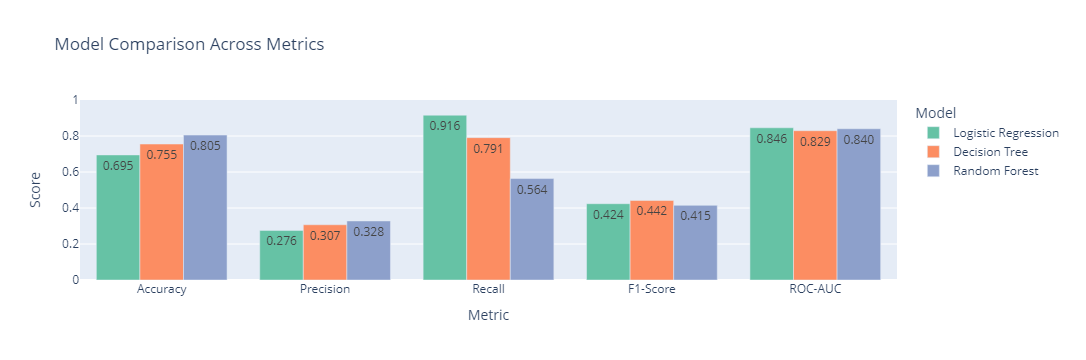

In [26]:
# Bar chart comparing all metrics across models
results_melt = results_df.reset_index().rename(columns={'index': 'Model'}).melt(
    id_vars='Model', var_name='Metric', value_name='Score')

fig = px.bar(results_melt, x='Metric', y='Score', color='Model', barmode='group',
             color_discrete_sequence=PALETTE, title='Model Comparison Across Metrics',
             text_auto='.3f')
fig.update_layout(yaxis_range=[0, 1])
fig.show()


In [27]:
# ROC curves for all three models on one chart
fig = go.Figure()
for name, proba in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    # Downsample points for a lighter, faster-rendering chart while preserving the curve shape
    idx = np.linspace(0, len(fpr) - 1, min(300, len(fpr))).astype(int)
    fig.add_trace(go.Scatter(x=fpr[idx], y=tpr[idx], mode='lines',
                              name=f"{name} (AUC={results[name]['ROC-AUC']:.3f})"))

fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(dash='dash', color='grey'),
                          name='Random Guess'))
fig.update_layout(title='ROC Curves -- Model Comparison',
                   xaxis_title='False Positive Rate', yaxis_title='True Positive Rate')
fig.show()


In [28]:
# Confusion matrices, side by side (all pipelines take the raw X_test)
fig = make_subplots(rows=1, cols=3, subplot_titles=list(models.keys()))
for i, (name, model) in enumerate(models.items(), start=1):
    cm = confusion_matrix(y_test, model.predict(X_test))
    fig.add_trace(go.Heatmap(z=cm, x=['Pred: No', 'Pred: Yes'], y=['Actual: No', 'Actual: Yes'],
                              text=cm, texttemplate='%{text}', colorscale='Blues', showscale=False),
                  row=1, col=i)
fig.update_layout(width=1200, height=400, title_text='Confusion Matrices (Test Set)')
fig.show()


**Inference -- picking the best model:**
- We use **ROC-AUC** as the primary yardstick because it is threshold-independent and suited to an imbalanced target. In this run the three models are **close**: Logistic Regression ~0.846, Random Forest ~0.840, Decision Tree ~0.829. Logistic Regression is marginally the highest (by about 0.005), helped by the engineered `Damage_NotInsured` feature, which hands the linear model the key interaction. The Decision Tree is clearly the weakest.
- At the default 0.5 threshold the models behave very differently. Logistic Regression flags roughly **41%** of all customers as "Interested" (recall 0.92, precision only 0.28), whereas Random Forest flags roughly **21%** (recall 0.56, precision 0.33) -- so the Random Forest has the best **precision and accuracy** and would contact about half as many customers.
- Look at the **Precision** and **Recall** columns / confusion matrices: because SMOTE rebalances the training data, the models flag a far larger share of customers as "Interested" than a naive model would, so recall for the "Yes" class is much higher than it would otherwise be -- at the cost of **low precision** (many flagged customers will still say no). For a marketing campaign that is an acceptable trade-off, since contacting a few extra uninterested customers is cheaper than missing an interested one. If the campaign budget is tight, the decision threshold can be raised to trade recall for precision.

**We select Random Forest as our final model** because its ROC-AUC is within about 0.006 of the best, it has the best precision/accuracy, it can capture non-linear effects and interactions beyond the hand-built features, and `TreeExplainer` gives exact SHAP explanations for it in the next section. If ranking quality (ROC-AUC) were the only goal, the simpler Logistic Regression would be an equally good choice.

> *Note: this choice is a judgement call, not a pure ROC-AUC ranking. If you re-run the notebook, re-check the comparison table above and revisit the selection if the gaps between the models change materially.*


## 15. Feature Importance with SHAP
**What SHAP does:** SHAP (SHapley Additive exPlanations) assigns every feature a contribution value for each individual prediction, based on game-theory principles. It tells us not just *which* features matter, but *how* they push predictions up or down. We use `TreeExplainer`, which is fast and exact for tree-based models like our Random Forest.

We compute SHAP values on a **random sample of 1,000 test rows** (instead of the full ~76k test set) -- this is standard practice, since SHAP is computationally expensive, and a well-chosen random sample gives a statistically reliable picture of global feature importance.

In [29]:
# Sample from the test set for SHAP (keeps computation fast, ~1,000 rows is a reliable sample).
# The forest was trained on un-scaled features, so we explain it with un-scaled X_test rows.
shap_sample = X_test.sample(1000, random_state=42)

explainer = shap.TreeExplainer(rand_forest)
shap_values = explainer.shap_values(shap_sample, check_additivity=False)

# For a binary classifier, shap_values is either a list of 2 arrays or one array of shape
# (rows, features, 2 classes) depending on the shap version. We take class 1 ("Interested").
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values[:, :, 1]

print("SHAP values computed for", shap_sample.shape[0], "sample rows.")


SHAP values computed for 1000 sample rows.


In [30]:
# Mean absolute SHAP value per feature = overall importance ranking
mean_abs_shap = np.abs(shap_values_class1).mean(axis=0)
shap_importance = pd.DataFrame({
    'Feature': shap_sample.columns,
    'Mean_|SHAP|': mean_abs_shap
}).sort_values('Mean_|SHAP|', ascending=False)

fig = px.bar(shap_importance, x='Mean_|SHAP|', y='Feature', orientation='h',
             color='Mean_|SHAP|', color_continuous_scale='Viridis',
             title='SHAP Feature Importance -- Random Forest (mean |SHAP value|)')
fig.update_layout(yaxis={'categoryorder': 'total ascending'}, height=550)
fig.show()

shap_importance


,Feature,Mean_|SHAP|
4,Previously_Insured,0.133260
10,Damage_NotInsured,0.082161
12,Young_Licensed_Driver,0.074666
6,Vehicle_Damage,0.066678
8,Policy_Sales_Channel,0.050942
16,Age_Group_60+,0.041827
14,Age_Group_40-49,0.041041
15,Age_Group_50-59,0.035481
1,Age,0.033843
13,Age_Group_30-39,0.028213


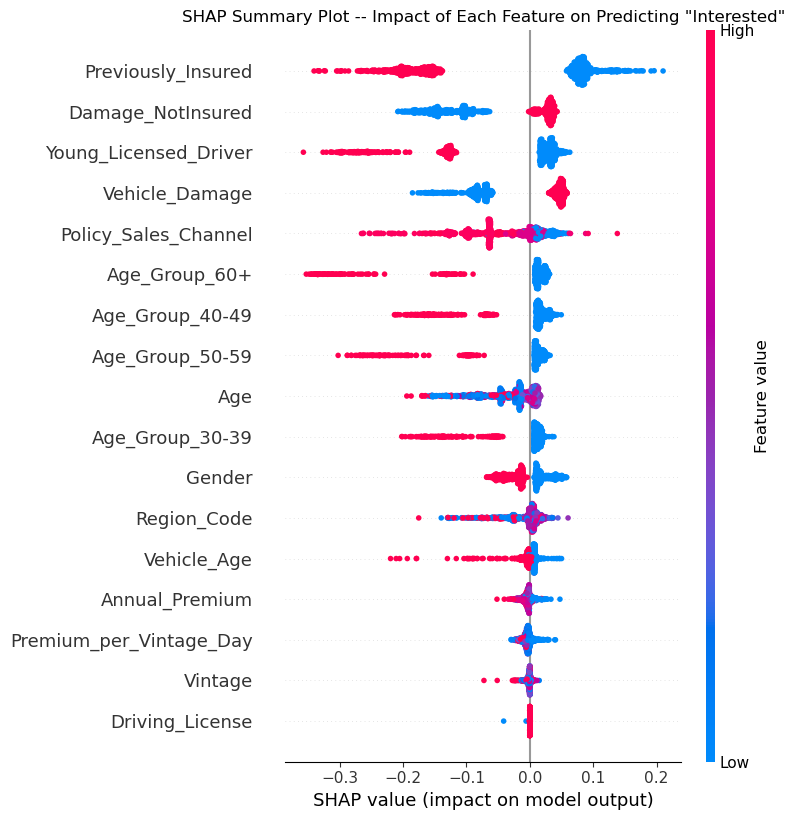

In [31]:
# SHAP summary (beeswarm) plot -- shows both importance AND the direction of each feature's effect.
# This uses shap's own matplotlib-based plotting since it's the clearest way to show
# the distribution of impact per feature (high/low feature value vs push toward Yes/No).
shap.summary_plot(shap_values_class1, shap_sample, show=False)
plt.title('SHAP Summary Plot -- Impact of Each Feature on Predicting "Interested"')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=120, bbox_inches='tight')
plt.show()


**Inference -- reading the SHAP results:**
- The bar chart ranks features by average impact on the prediction. In our run the top five are `Previously_Insured` (clearly first), `Damage_NotInsured`, `Young_Licensed_Driver`, `Vehicle_Damage` and `Policy_Sales_Channel`. This matches the EDA: the insured/damage features dominate, and because `Previously_Insured`, `Vehicle_Damage` and `Damage_NotInsured` overlap heavily (see the correlation section), SHAP *splits* their credit between them.
- **Surprise: `Young_Licensed_Driver` ranks third.** This flag (Age <= 25 with a licence) covers about 30% of customers, who respond only ~3.5% of the time versus 12% overall, so it is a clean and strong age split.
- Age information is spread over several columns (`Age`, the `Age_Group_*` dummies and `Young_Licensed_Driver`) that all encode the same variable, so SHAP shares the credit between them. In the beeswarm the `Age_Group_*` dummies show red (=1) dots on the left, which can look like it contradicts the EDA -- but each dummy is relative to the 20-29 reference group and overlaps with the other age columns, so a single dummy should not be read in isolation. Judge the non-linear age effect (low for 20-29, highest for 30-49, lower again for 60+) from the EDA response-rate chart in Section 6.
- `Driving_License` (>99% of customers have one), `Vintage`, `Premium_per_Vintage_Day` and `Annual_Premium` sit at the bottom of the chart, consistent with the EDA, where they showed little relationship with the target.
- In the beeswarm plot, each dot is a customer, the x-position is the push towards "Interested" (right) or "Not Interested" (left), and colour is the feature value. For a 0/1 feature, red = 1. As expected, red `Previously_Insured` dots (already insured) sit on the left, while red `Vehicle_Damage` and `Damage_NotInsured` dots (previous damage) sit on the right -- matching business intuition.


## 16. Conclusions & Business Recommendations

**Model Performance Summary**
- All three models rank customers far better than random (test ROC-AUC 0.83-0.85) and are close to each other (Logistic Regression 0.846, Random Forest 0.840, Decision Tree 0.829). **Random Forest** is our recommended model for its best precision (0.33) and accuracy (0.81), contacting about half as many customers as Logistic Regression at the default threshold; Logistic Regression is a near-equal, simpler alternative.
- Precision for the "Yes" class is low (roughly 1 in 3 flagged customers actually accepts) -- the model is best used to **rank and prioritise** customers rather than as a yes/no oracle.
- Using SMOTE on the training data (while keeping the test set untouched) allowed the models to learn the minority ("Yes") class properly, instead of just predicting the majority class every time.

**Key Business Insights**
1. **Target customers with prior vehicle damage who are not currently insured** -- this single combination (`Damage_NotInsured`) identifies the highest-converting segment in the entire dataset.
2. **De-prioritize already-insured customers** -- they almost never respond positively to a cross-sell offer; reallocating marketing budget away from them will improve ROI.
3. **Middle-aged customers (30-59) and older vehicles** convert better than young customers with new vehicles -- marketing messaging and channel selection should be tailored by age segment.
4. **Sales channel matters, but partly through age** -- `Policy_Sales_Channel` is correlated with both `Response` and `Age`, so the sales team should investigate which channels convert best *within* comparable age groups before shifting volume.

**Suggested Next Steps**
- Deploy the Random Forest model to score new/existing customers and produce a ranked "propensity to buy" list for the sales team.
- Run a larger-scale hyperparameter search (more iterations/folds, ideally on a multi-core machine) and test gradient-boosted models (XGBoost/LightGBM) for a potential further performance boost.
- Try `SMOTENC` (or class weights) instead of plain SMOTE: plain SMOTE interpolates between customers, which creates fractional values for code/binary columns such as `Region_Code`, `Policy_Sales_Channel` or `Gender`.
- Tune the decision threshold to match the campaign's cost of contacting a customer versus the value of a conversion.
- Periodically retrain the model as new response data comes in, since customer behaviour and channel performance can shift over time.


## 17. Save the Final Model
The saved model files are listed in `.gitignore` (they can be large); re-running this notebook regenerates them.

In [32]:
# Save the final Random Forest (trained on un-scaled features, so no scaler is needed).
# joblib with compression keeps the file small; pickles of large forests can exceed GitHub's 100 MB file limit.
joblib.dump(rand_forest, 'random_forest_model.joblib', compress=3)

# Save the exact feature order the model expects, so it can be used for scoring later
with open('feature_columns.json', 'w') as f:
    json.dump(list(X_train.columns), f)

size_mb = Path('random_forest_model.joblib').stat().st_size / 1e6
print(f"Random Forest saved to random_forest_model.joblib ({size_mb:.1f} MB) and feature order to feature_columns.json")


Random Forest saved to random_forest_model.joblib (19.7 MB) and feature order to feature_columns.json
